In [11]:
import matplotlib.pyplot as plt
import numpy as np

from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score


In [12]:
# --------------------------------------------------
# 1. Generate the Make Moons dataset
# --------------------------------------------------

X, y_true = make_moons(n_samples=500,noise=0.08,random_state=42)

print("Dataset shape:", X.shape)

Dataset shape: (500, 2)


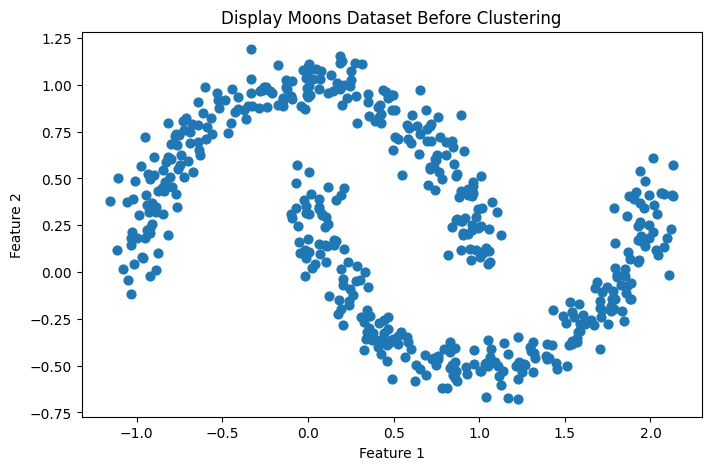

In [13]:
# --------------------------------------------------
# 2. Visualize data BEFORE clustering
# --------------------------------------------------

plt.figure(figsize=(8, 5))

plt.scatter(
    X[:, 0],
    X[:, 1],
    s=40
)

plt.title("Display Moons Dataset Before Clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")

plt.show()



In [14]:
# --------------------------------------------------
# 3. Standardize the features
# --------------------------------------------------

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [15]:
# --------------------------------------------------
# 4. Apply DBSCAN clustering
# --------------------------------------------------

dbscan = DBSCAN(eps=0.3,min_samples=5)

y_pred = dbscan.fit_predict(X_scaled)

In [16]:
# --------------------------------------------------
# 5. Display clustering results
# --------------------------------------------------

n_clusters = len(set(y_pred) - {-1})
n_noise = np.sum(y_pred == -1)

print("\nNumber of clusters:", n_clusters)
print("Number of noise points:", n_noise)

print("\nCluster labels:", np.unique(y_pred))




Number of clusters: 2
Number of noise points: 0

Cluster labels: [0 1]


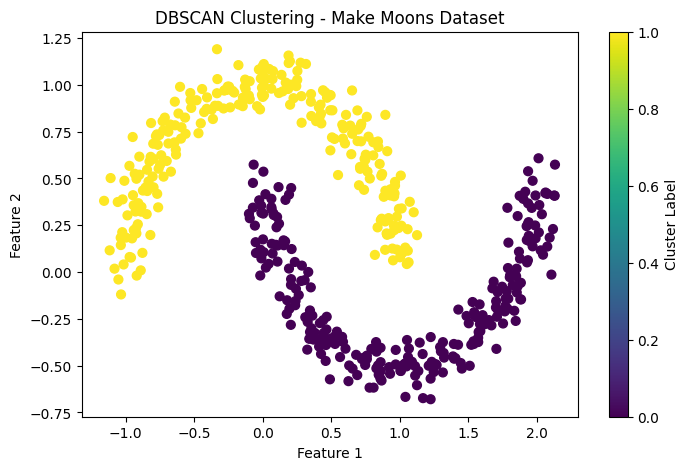

In [17]:
# --------------------------------------------------
# 6. Visualize data AFTER clustering
# --------------------------------------------------

plt.figure(figsize=(8, 5))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=y_pred,
    cmap="viridis",
    s=40
)

plt.title("DBSCAN Clustering - Make Moons Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")

plt.colorbar(label="Cluster Label")

plt.show()



In [18]:
# --------------------------------------------------
# 7. Calculate Silhouette Score
# --------------------------------------------------

# Exclude noise points from silhouette calculation
non_noise = y_pred != -1

X_clustered = X_scaled[non_noise]

labels_clustered = y_pred[non_noise]

# Silhouette score requires at least 2 clusters
if len(np.unique(labels_clustered)) >= 2:

    score = silhouette_score(
        X_clustered,
        labels_clustered
    )

    print("\nSilhouette Score:", score)

else:

    print("\nSilhouette Score cannot be calculated.")
    print("At least two non-noise clusters are required.")





Silhouette Score: 0.38355256771289353
